# Isotonic calibration

This notebook calibrates the predicted probabilities of all trained models and compares them before and after calibration.
Calibration is fitted on the calibration split for every model saved in `models/`; calibrated models go to `model_calibrated_isotonic/` and metrics to `results/isotonic/`.

The functions used are documented in `src/calibration_utils.py`.

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

from src.calibration_utils import calibrate_all_models, plot_all_calibration_comparison

In [6]:
# =============================================================================
# CELL 1: LOAD DATA
# =============================================================================

# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Load the three splits
print("Loading data...")

cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Split features / target
X_cal = cal_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_cal = cal_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print("Data loaded:")
print(f"   - Calibration: {X_cal.shape[0]} lignes, {X_cal.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes, {X_test.shape[1]} features")

Loading data...
Data loaded:
   - Calibration: 56725 lignes, 81 features
   - Test: 56938 lignes, 81 features


In [7]:
# =============================================================================
# CELL 2: CALIBRATE ALL MODELS (ISOTONIC)
# =============================================================================

# Calibrate every saved model with isotonic regression
results_df = calibrate_all_models(
    model_dir='models',
    output_dir='model_calibrated_isotonic',
    X_cal=X_cal,
    y_cal=y_cal,
    X_test=X_test,
    y_test=y_test,
    method='isotonic',  # Isotonic Regression
    pattern='*_tuned.pkl',
    save_plots=True,
    plot_dir='model_calibrated_isotonic/plots',
    save_results_dir='results/isotonic'
)

print("\nIsotonic calibration finished.")

Models found in 'models':
   - logistic_regression_tuned.pkl
   - gradient_boosting_tuned.pkl
   - random_forest_tuned.pkl
   - xgboost_tuned.pkl

CALIBRATING 4 MODELS
   Method: isotonic
   Calibration data: 56725 samples
   Test data: 56938 samples

──────────────────────────────────────────────────
Model: logistic_regression
──────────────────────────────────────────────────
   ✓ Model loaded: models/logistic_regression_tuned.pkl
   Calibrating with method: isotonic

   Test set metrics:
      Brier Score:   0.1928 → 0.1931 (↑ 0.0002)
      Log Loss:      0.5679 → 0.5714 (↑ 0.0035)
      ROC-AUC:       0.7761 → 0.7759
   ✓ Plot saved: results/isotonic/logistic_regression_calibrated/logistic_regression_calibration_curve.png
   ✓ Metrics saved: results/isotonic/logistic_regression_calibrated/logistic_regression_calibrated_metrics.csv
   ✓ Results saved: results/isotonic/logistic_regression_calibrated/logistic_regression_calibrated_results.txt
   ✓ Calibrated model saved: model_calibra

✓ Comparison saved: model_calibrated_isotonic/comparison_calibration_isotonic.png


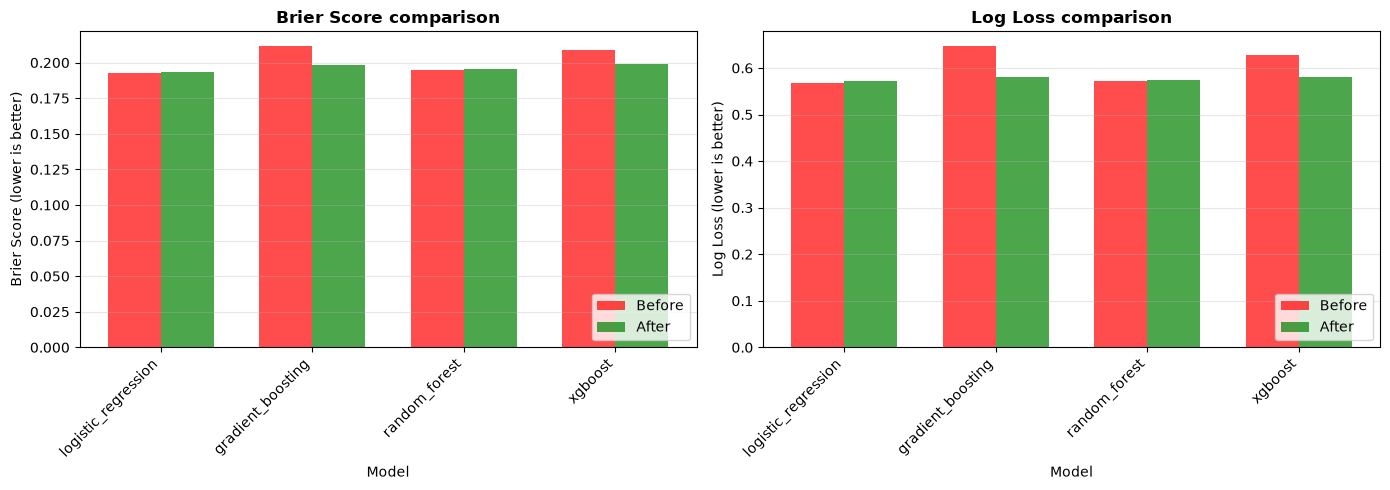


Summary table (isotonic):
              model  brier_before  brier_after  log_loss_before  log_loss_after  roc_auc_before  roc_auc_after  brier_improvement  log_loss_improvement
logistic_regression      0.192844     0.193073         0.567907        0.571409        0.776075       0.775948          -0.000229             -0.003502
  gradient_boosting      0.211388     0.198361         0.646383        0.581486        0.759809       0.759668           0.013028              0.064898
      random_forest      0.194846     0.195543         0.572585        0.574815        0.769605       0.769378          -0.000696             -0.002230
            xgboost      0.208874     0.198707         0.627587        0.581478        0.760861       0.760617           0.010167              0.046109


In [8]:
# =============================================================================
# CELL 3: COMPARISON PLOTS
# =============================================================================

# Compare all models
fig = plot_all_calibration_comparison(
    results_df, 
    save_path='model_calibrated_isotonic/comparison_calibration_isotonic.png'
)
plt.show()

# Summary table
print("\nSummary table (isotonic):")
print(results_df.to_string(index=False))

## Conclusion

Isotonic regression gives slightly larger gains than Platt scaling on the two boosting models: log loss drops from 0.646 to 0.581 for gradient boosting (−10.0%) and from 0.628 to 0.581 for XGBoost (−7.3%), against 0.585–0.586 with Platt scaling. It slightly worsens the two models that were already well calibrated (log loss 0.568 → 0.571 for logistic regression, 0.573 → 0.575 for random forest). ROC-AUC decreases very slightly (by at most 0.0003), because the isotonic step function creates ties between pairs. Logistic regression remains the best model after either calibration method.